# Apex Lark – Data Analytics Internship | Day 07
## Business Data Analysis Using Python & Pandas

**Scenario:** A retail company exported its monthly sales data to CSV. This notebook automates the analysis: load → quality check → clean → KPIs → filtering → grouping → visualisation → insights.

**Sections**
1. Environment setup
2. Load the dataset
3. Data quality assessment (raw data)
4. Data cleaning
5. Business KPIs
6. Data filtering
7. Data grouping
8. Visualisations
9. Business insights & recommendations

## 1. Environment Setup

In [1]:
# Install once if needed:  pip install pandas numpy matplotlib
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)

DATA_PATH = "sales_data.csv"     # raw CSV (keep next to this notebook)
CHART_DIR = "charts"             # charts are saved here
os.makedirs(CHART_DIR, exist_ok=True)

# Parameters used in the filtering section
SALES_THRESHOLD = 100_000        # "orders with sales greater than ..."
SELECTED_REGION = "South"        # region used for the region filter

## 2. Load the Dataset

In [2]:
raw = pd.read_csv(DATA_PATH)
print(f"Rows: {raw.shape[0]:,} | Columns: {raw.shape[1]}")

Rows: 4,310 | Columns: 21


**First 10 records**

In [3]:
raw.head(10)

,order_id,order_date,customer_id,customer_name,age,gender,region,city,product_category,product_name,quantity,unit_price,discount_pct,sales_amount,profit,shipping_cost,payment_method,customer_satisfaction,return_flag,order_status,days_to_ship
0,ORD-03903,2024-08-15,CUST32603,Aarav Mehta,39.00,Other,Central,Raipur,Groceries,Sugar,8.00,346.32,NaN,"4,043.14",289.18,56.04,Debit Card,NaN,True,Returned,7.00
1,ORD-02198,2022-08-16,CUST07881,Sanjay Verma,28.00,Male,West,Mumbai,Beauty,Sunscreen,8.00,858.66,0.08,"9,147.31","5,355.56",64.49,Debit Card,5.00,False,Delivered,2.00
2,ORD-01348,2021-08-29,CUST49296,Pooja Sharma,41.00,Other,West,Surat,Furniture,Sofa,4.00,"25,941.32",0.14,"110,156.97","36,956.51",67.65,Debit Card,4.00,False,Delivered,5.00
3,ORD-02076,2022-07-05,CUST05587,Priya Reddy,29.00,Other,West,Ahmedabad,Furniture,Bed Frame,9.00,"22,071.92",0.17,"262,066.11","66,644.99",54.47,EMI,3.00,False,Delivered,4.00
4,ORD-00287,2020-05-07,CUST58035,Ritu Sharma,9.00,Male,Central,Nagpur,Groceries,Cooking Oil,1.00,320.06,0.31,323.95,31.38,48.81,Net Banking,4.00,False,Pending,4.00
5,ORD-03954,02/09/2024,CUST17187,Vikram Iyer,29.00,Male,West,Surat,Books,Self-Help Book,2.00,949.50,0.22,"2,202.33",964.66,62.42,Cash on Delivery,2.00,True,Returned,8.00
6,ORD-01412,2021-09-28,CUST02453,Arjun Shah,31.00,Female,Central,Bhopal,Books,Self-Help Book,3.00,329.03,0.02,994.87,375.07,77.34,Credit Card,5.00,True,Returned,10.00
7,ORD-02911,2023-06-10,CUST23285,Aditya Sharma,43.00,Female,North,Amritsar,Clothing,Saree,1.00,"1,356.60",0.01,"2,140.41",717.27,82.68,UPI,1.00,False,Delivered,4.00
8,ORD-00465,2020-07-24,CUST23609,Aditya Patel,44.00,Female,East,Patna,Books,Self-Help Book,8.00,495.77,0.37,"2,828.82","1,338.88",84.50,Debit Card,1.00,False,Cancelled,10.00
9,ORD-00105,2020-02-09,CUST75337,Arjun Das,17.00,FEMALE,East,Patna,Clothing,Kurta,9.00,"2,128.77",0.10,"14,568.16","4,173.45",75.33,UPI,3.00,False,Delivered,8.00


**Last 10 records**

In [4]:
raw.tail(10)

,order_id,order_date,customer_id,customer_name,age,gender,region,city,product_category,product_name,quantity,unit_price,discount_pct,sales_amount,profit,shipping_cost,payment_method,customer_satisfaction,return_flag,order_status,days_to_ship
4300,ORD-02023,2022-06-10,CUST72866,Vikram Mishra,41.00,Male,North,Amritsar,Sports,Tennis Racket,4.00,"11,418.62",0.21,"52,022.28","11,855.66",52.64,Cash on Delivery,2.00,False,Delivered,1.00
4301,ORD-00060,2020-01-22,CUST06516,Pooja Das,41.00,Female,South,Bangalore,Sports,Cricket Bat,3.00,"14,511.24",NaN,"36,886.86","8,351.78",63.58,EMI,3.00,False,Delivered,3.00
4302,ORD-00177,2020-03-18,CUST74936,Aditya Sharma,49.00,Female,West,Mumbai,Clothing,Jacket,9.00,"2,298.37",NaN,"20,461.06","7,107.09",64.34,Debit Card,3.00,False,Delivered,2.00
4303,ORD-00450,2020-07-17,CUST20483,Kavya Iyer,29.00,Other,South,Chennai,Furniture,Wardrobe,10.00,"9,945.43",0.24,"94,093.98","30,233.13",76.34,Credit Card,3.00,False,Delivered,10.00
4304,ORD-04082,2024-11-05,CUST72244,Aditya Patel,19.00,Female,East,Guwahati,Groceries,Cooking Oil,10.00,400.50,0.32,"2,696.95",174.53,55.61,EMI,4.00,False,Delivered,9.00
4305,ORD-00056,2020-01-21,CUST85136,Sanjay Sharma,45.00,F,West,Pune,Sports,Football,6.00,"1,871.46",0.22,"6,895.34","1,811.03",62.59,EMI,NaN,True,Returned,9.00
4306,ORD-03458,2024-02-08,CUST09746,Karan Pillai,25.00,m,South,Chennai,Clothing,Kurta,7.00,"3,147.97",0.13,"22,125.94","10,153.44",38.76,EMI,2.00,False,Cancelled,2.00
4307,ORD-01769,2022-02-22,CUST64190,Karan Reddy,39.00,Male,East,Guwahati,Beauty,Face Cream,7.00,422.45,0.02,"2,726.49",759.36,39.41,Credit Card,NaN,False,Delivered,5.00
4308,ORD-01738,2022-02-11,CUST50460,Amit Mehta,40.00,Female,East,Bhubaneswar,Books,Biography,5.00,"1,456.57",0.27,"4,835.66","2,312.44",71.90,Cash on Delivery,1.00,False,Cancelled,4.00
4309,ORD-03241,2023-11-01,CUST36164,Nikhil Rao,23.00,Other,North,Delhi,Furniture,Desk,10.00,"28,349.81",0.14,"211,857.48","59,966.21",53.88,Debit Card,2.00,False,Delivered,2.00


**Dataset information**

In [5]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 4310 entries, 0 to 4309
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               4280 non-null   str    
 1   order_date             4280 non-null   str    
 2   customer_id            4280 non-null   str    
 3   customer_name          4280 non-null   str    
 4   age                    4150 non-null   float64
 5   gender                 4280 non-null   str    
 6   region                 4280 non-null   str    
 7   city                   4280 non-null   str    
 8   product_category       4280 non-null   str    
 9   product_name           4280 non-null   str    
 10  quantity               4170 non-null   float64
 11  unit_price             4280 non-null   float64
 12  discount_pct           4143 non-null   float64
 13  sales_amount           4280 non-null   float64
 14  profit                 4280 non-null   float64
 15  shipping_cost  

**Descriptive statistics (numeric columns)**

In [6]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
age,"4,150.00",35.34,35.71,-7.00,26.00,34.00,42.00,999.00
quantity,"4,170.00",7.38,43.58,-1.00,3.00,5.00,8.00,999.00
unit_price,"4,280.00","10,621.15","17,323.70",50.26,672.22,"2,228.43","12,717.43","79,957.92"
discount_pct,"4,143.00",0.20,0.12,0.00,0.10,0.21,0.31,0.40
sales_amount,"4,280.00","62,358.64","316,699.81",39.45,"2,462.16","9,548.08","50,069.64","17,360,314.17"
profit,"4,280.00","11,687.13","52,875.22",1.56,701.82,"3,128.01","10,403.72","2,445,648.43"
shipping_cost,"4,280.00",63.36,18.31,-4.29,50.82,63.47,75.65,133.35
customer_satisfaction,"3,932.00",3.02,1.41,1.00,2.00,3.00,4.00,5.00
days_to_ship,"4,180.00",5.62,4.18,-1.00,3.00,6.00,8.00,100.00


**Column names and data types**

In [7]:
pd.DataFrame({"column": raw.columns, "dtype": raw.dtypes.astype(str).values})

,column,dtype
0,order_id,str
1,order_date,str
2,customer_id,str
3,customer_name,str
4,age,float64
5,gender,str
6,region,str
7,city,str
8,product_category,str
9,product_name,str


## 3. Data Quality Assessment (raw data)
Every issue is identified first on the **raw** data, then handled in Section 4.

### 3.1 Missing values

In [8]:
missing = raw.isna().sum()
missing_report = pd.DataFrame({"missing": missing, "pct": (missing / len(raw) * 100).round(2)})
missing_report[missing_report["missing"] > 0].sort_values("missing", ascending=False)

,missing,pct
customer_satisfaction,378,8.77
discount_pct,167,3.87
age,160,3.71
quantity,140,3.25
days_to_ship,130,3.02
customer_name,30,0.70
customer_id,30,0.70
order_date,30,0.70
order_id,30,0.70
product_category,30,0.70


In [9]:
fully_blank = raw.isna().all(axis=1).sum()
print(f"Completely blank rows: {fully_blank}")

Completely blank rows: 30


### 3.2 Duplicate records

In [10]:
exact_dups = raw.duplicated().sum()
non_blank = raw.dropna(how="all")
dup_orders = non_blank.duplicated().sum()
print(f"Exact duplicate rows (incl. repeated blank rows): {exact_dups}")
print(f"Exact duplicate ORDER records (blank rows excluded): {dup_orders}")
print(f"order_id repeated but rows differ: {non_blank['order_id'].duplicated().sum() - dup_orders}")

Exact duplicate rows (incl. repeated blank rows): 109
Exact duplicate ORDER records (blank rows excluded): 80
order_id repeated but rows differ: 0


### 3.3 Unique values in categorical columns

In [11]:
cat_cols = ["gender", "region", "city", "product_category", "payment_method", "order_status", "return_flag"]
for col in cat_cols:
    vals = raw[col].dropna().unique()
    print(f"\n{col}  ({len(vals)} unique)")
    print(sorted(map(str, vals)))


gender  (11 unique)
['F', 'FEMALE', 'Female', 'M', 'MALE', 'Male', 'Other', 'f', 'female', 'm', 'male']

region  (5 unique)
['Central', 'East', 'North', 'South', 'West']

city  (20 unique)
['Ahmedabad', 'Amritsar', 'Bangalore', 'Bhopal', 'Bhubaneswar', 'Chandigarh', 'Chennai', 'Delhi', 'Guwahati', 'Hyderabad', 'Indore', 'Kochi', 'Kolkata', 'Ludhiana', 'Mumbai', 'Nagpur', 'Patna', 'Pune', 'Raipur', 'Surat']

product_category  (7 unique)
['Beauty', 'Books', 'Clothing', 'Electronics', 'Furniture', 'Groceries', 'Sports']

payment_method  (6 unique)
['Cash on Delivery', 'Credit Card', 'Debit Card', 'EMI', 'Net Banking', 'UPI']

order_status  (9 unique)
['Cancelled', 'Delivered', 'Pending', 'Returned', 'Shipped', 'cancelled', 'delivered', 'pending', 'shipped']

return_flag  (2 unique)
['False', 'True']


### 3.4 Invalid or inconsistent records

In [12]:
nb = raw.dropna(how="all")
date_text = nb["order_date"].astype(str)
iso      = date_text.str.match(r"^\d{4}-\d{2}-\d{2}$")
slash    = date_text.str.contains("/")
longform = ~iso & ~slash

issues = {
    "Mixed date formats: ISO (YYYY-MM-DD)":         int(iso.sum()),
    "Mixed date formats: DD/MM/YYYY":               int(slash.sum()),
    "Mixed date formats: 'Month DD, YYYY'":         int(longform.sum()),
    "Gender spelled inconsistently (case/abbrev.)": int((~nb["gender"].isin(["Male", "Female", "Other"]) & nb["gender"].notna()).sum()),
    "order_status has inconsistent case":           int((nb["order_status"].notna() & (nb["order_status"] != nb["order_status"].str.title())).sum()),
    "quantity <= 0":                                int((nb["quantity"] <= 0).sum()),
    "quantity = 999 (placeholder / outlier)":       int((nb["quantity"] > 100).sum()),
    "age <= 0 or age > 100":                        int(((nb["age"] <= 0) | (nb["age"] > 100)).sum()),
    "age between 1 and 12 (implausible buyers)":    int(nb["age"].between(1, 12).sum()),
    "shipping_cost < 0":                            int((nb["shipping_cost"] < 0).sum()),
    "days_to_ship < 0":                             int((nb["days_to_ship"] < 0).sum()),
    "days_to_ship > 60":                            int((nb["days_to_ship"] > 60).sum()),
}
pd.Series(issues, name="records").to_frame()

,records
Mixed date formats: ISO (YYYY-MM-DD),4007
Mixed date formats: DD/MM/YYYY,150
"Mixed date formats: 'Month DD, YYYY'",123
Gender spelled inconsistently (case/abbrev.),440
order_status has inconsistent case,156
quantity <= 0,18
quantity = 999 (placeholder / outlier),8
age <= 0 or age > 100,26
age between 1 and 12 (implausible buyers),132
shipping_cost < 0,2


In [13]:
# customer_id reliability: should map 1-to-1 with customer_name
unique_ids   = nb["customer_id"].nunique()
unique_names = nb["customer_name"].nunique()
ids_many_names = (nb.groupby("customer_id")["customer_name"].nunique() > 1).sum()
print(f"Unique customer_id: {unique_ids:,}  |  Unique customer_name: {unique_names}")
print(f"customer_id values attached to more than one name: {ids_many_names}")

# does sales_amount reconcile with quantity x unit_price x (1 - discount)?
expected = nb["quantity"] * nb["unit_price"] * (1 - nb["discount_pct"].fillna(0))
ratio = (nb["sales_amount"] / expected).replace([np.inf, -np.inf], np.nan)
print(f"sales_amount within +/-5% of qty x price x (1-disc): {ratio.between(0.95, 1.05).mean():.1%} of rows")

# status vs return flag
pd.crosstab(nb["order_status"].str.title(), nb["return_flag"])

Unique customer_id: 4,112  |  Unique customer_name: 400
customer_id values attached to more than one name: 87
sales_amount within +/-5% of qty x price x (1-disc): 10.9% of rows


return_flag,False,True
order_status,,
Cancelled,352,0
Delivered,2787,0
Pending,184,0
Returned,0,623
Shipped,334,0


### 3.5 Observations (documented)

| # | Observation | Treatment |
|---|---|---|
| 1 | **30 completely blank rows** | Dropped |
| 2 | **80 exact duplicate orders** (same `order_id`, identical values) | Duplicates removed, first kept |
| 3 | `order_date` stored in **three formats** (ISO, `DD/MM/YYYY`, `Month DD, YYYY`) | Parsed per format into one datetime column. Slash dates treated as **day-first**: 83 have a day > 12 and none has a month > 12, so month-first is impossible |
| 4 | `gender` has 11 spellings (`male`, `MALE`, `m`, `F`, ...) | Standardised to Male / Female / Other |
| 5 | `order_status` has mixed case (`delivered`, `Delivered`) | Standardised to Title Case |
| 6 | **`quantity` = 999** (8 rows) and `quantity` <= 0 (18 rows) | Treated as invalid entries and **excluded from the analysis**. The 999 rows alone carry about Rs 32M, roughly 12% of raw sales, and would distort every ranking |
| 7 | `age` of 999 or negative; many ages under 13 | 999 / negative set to missing. Age is not used in any KPI |
| 8 | Negative `shipping_cost` and `days_to_ship`; `days_to_ship` up to 100 | Set to missing |
| 9 | Missing values in `age`, `quantity`, `discount_pct`, `customer_satisfaction`, `days_to_ship` | Left as missing. None is needed for revenue or profit KPIs |
| 10 | **`customer_id` is unreliable**: about 4,100 distinct IDs across 4,200 orders, and 87 IDs map to more than one name | **`customer_name`** (400 unique) is used for all customer-level analysis |
| 11 | `sales_amount` does **not** reconcile with quantity x price x (1 - discount) | Used **as recorded**, since it is the company's own revenue field. Flagged for follow-up with the data owner |
| 12 | 15% of orders are Returned and 8% Cancelled | Kept in the main KPIs and shown in a sensitivity check (Section 5.3) |

## 4. Data Cleaning
Cleaning is wrapped in small, single-purpose functions so each step is easy to audit.

In [14]:
def parse_mixed_dates(series: pd.Series) -> pd.Series:
    """Parse ISO, DD/MM/YYYY and 'Month DD, YYYY' strings into datetimes."""
    text = series.astype(str)
    is_iso   = text.str.match(r"^\d{4}-\d{2}-\d{2}$")
    is_slash = text.str.contains("/")
    is_long  = ~is_iso & ~is_slash
    parsed = pd.to_datetime(text.where(is_iso), format="%Y-%m-%d", errors="coerce")
    parsed = parsed.fillna(pd.to_datetime(text.where(is_slash), format="%d/%m/%Y", errors="coerce"))
    parsed = parsed.fillna(pd.to_datetime(text.where(is_long), format="%B %d, %Y", errors="coerce"))
    return parsed


def standardise_gender(series: pd.Series) -> pd.Series:
    key = series.str.strip().str.lower().str[0]
    return key.map({"m": "Male", "f": "Female", "o": "Other"})


def clean_sales_data(df: pd.DataFrame):
    """Return (clean_df, log) where log records how many rows each step touched."""
    log = {"raw rows": len(df)}
    df = df.dropna(how="all")
    log["after dropping blank rows"] = len(df)
    df = df.drop_duplicates()
    log["after dropping duplicate orders"] = len(df)

    df = df.copy()
    df["order_date"] = parse_mixed_dates(df["order_date"])
    df["gender"] = standardise_gender(df["gender"])
    df["order_status"] = df["order_status"].str.strip().str.title()
    df["return_flag"] = df["return_flag"].astype(bool)

    # impossible values -> missing (these columns are not used in revenue KPIs)
    df.loc[(df["age"] <= 0) | (df["age"] > 100), "age"] = np.nan
    df.loc[df["shipping_cost"] < 0, "shipping_cost"] = np.nan
    df.loc[(df["days_to_ship"] < 0) | (df["days_to_ship"] > 60), "days_to_ship"] = np.nan

    # invalid quantity (999 placeholder, zero/negative) -> drop the order from analysis
    bad_qty = (df["quantity"] <= 0) | (df["quantity"] > 100)
    log["orders removed for invalid quantity"] = int(bad_qty.sum())
    df = df[~bad_qty]
    log["final analysis rows"] = len(df)

    df["year"] = df["order_date"].dt.year
    df["month"] = df["order_date"].dt.month
    df["year_month"] = df["order_date"].dt.to_period("M")
    return df.reset_index(drop=True), log


df, cleaning_log = clean_sales_data(raw)
pd.Series(cleaning_log, name="rows").to_frame()

,rows
raw rows,4310
after dropping blank rows,4280
after dropping duplicate orders,4200
orders removed for invalid quantity,26
final analysis rows,4174


In [15]:
# Post-cleaning validation
print("Unparsed dates:", df["order_date"].isna().sum())
print("Date range    :", df["order_date"].min().date(), "->", df["order_date"].max().date())
print("Genders       :", sorted(df["gender"].unique()))
print("Order status  :", sorted(df["order_status"].unique()))
print("Duplicate order_id:", df["order_id"].duplicated().sum())

Unparsed dates: 0
Date range    : 2020-01-01 -> 2024-12-30
Genders       : ['Female', 'Male', 'Other']
Order status  : ['Cancelled', 'Delivered', 'Pending', 'Returned', 'Shipped']
Duplicate order_id: 0


## 5. Business Analysis – KPIs

*Customer-level KPIs use `customer_name` (see observation 10). Revenue means `sales_amount` as recorded.*

In [16]:
total_sales   = df["sales_amount"].sum()
total_profit  = df["profit"].sum()
avg_sales     = df["sales_amount"].mean()
total_orders  = df["order_id"].nunique()
n_customers   = df["customer_name"].nunique()
n_products    = df["product_name"].nunique()

product_sales = df.groupby("product_name")["sales_amount"].sum().sort_values(ascending=False)
product_units = df.groupby("product_name")["quantity"].sum().sort_values(ascending=False)
category_rev  = df.groupby("product_category")["sales_amount"].sum().sort_values(ascending=False)

kpis = pd.Series({
    "Total Sales (Rs)":                    total_sales,
    "Total Profit (Rs)":                   total_profit,
    "Profit Margin (%)":                   total_profit / total_sales * 100,
    "Average Sales per Order (Rs)":        avg_sales,
    "Total Orders":                        total_orders,
    "Unique Customers":                    n_customers,
    "Number of Products Sold":             n_products,
})
kpis.to_frame("value")

,value
Total Sales (Rs),"232,336,302.24"
Total Profit (Rs),"42,993,161.20"
Profit Margin (%),18.50
Average Sales per Order (Rs),"55,662.75"
Total Orders,"4,174.00"
Unique Customers,400.00
Number of Products Sold,42.00


In [17]:
print(f"Best-selling product by revenue : {product_sales.index[0]}  (Rs {product_sales.iloc[0]:,.0f})")
print(f"Best-selling product by units   : {product_units.index[0]}  ({product_units.iloc[0]:,.0f} units)")
print(f"Highest-revenue category        : {category_rev.index[0]}  (Rs {category_rev.iloc[0]:,.0f})")

Best-selling product by revenue : Laptop  (Rs 26,799,205)
Best-selling product by units   : Laptop  (651 units)
Highest-revenue category        : Electronics  (Rs 138,155,175)


**Top 10 customers by sales**

In [18]:
top_customers = (df.groupby("customer_name")["sales_amount"].sum()
                   .sort_values(ascending=False).head(10))
top_customers.to_frame("total_sales")

,total_sales
customer_name,
Nisha Joshi,"2,360,876.34"
Meera Kapoor,"2,172,910.76"
Rohan Mehta,"2,063,836.76"
Sanjay Rao,"2,060,455.89"
Amit Shah,"1,955,359.66"
Vikram Mishra,"1,840,315.82"
Arjun Rao,"1,808,750.40"
Pooja Mishra,"1,730,400.35"
Ananya Gupta,"1,698,360.13"


**Top 5 cities by revenue**

In [19]:
top_cities = (df.groupby("city")["sales_amount"].sum()
                .sort_values(ascending=False).head(5))
top_cities.to_frame("total_sales")

,total_sales
city,
Chennai,"17,270,256.59"
Hyderabad,"13,621,541.06"
Mumbai,"13,476,757.87"
Kolkata,"13,398,236.29"
Amritsar,"12,455,689.01"


### 5.3 Sensitivity check: do the conclusions change if Cancelled / Returned orders are excluded?

In [20]:
def headline(frame: pd.DataFrame) -> dict:
    return {
        "orders": len(frame),
        "total_sales": frame["sales_amount"].sum(),
        "total_profit": frame["profit"].sum(),
        "top_region": frame.groupby("region")["sales_amount"].sum().idxmax(),
        "top_profit_category": frame.groupby("product_category")["profit"].sum().idxmax(),
        "top_month": str(frame.groupby("year_month")["sales_amount"].sum().idxmax()),
        "top_customer": frame.groupby("customer_name")["sales_amount"].sum().idxmax(),
    }

scenarios = {
    "All cleaned orders (used in this report)": df,
    "Excluding Cancelled":                      df[df["order_status"] != "Cancelled"],
    "Excluding Cancelled and Returned":         df[~df["order_status"].isin(["Cancelled", "Returned"])],
}
pd.DataFrame({name: headline(frame) for name, frame in scenarios.items()}).T

,orders,total_sales,total_profit,top_region,top_profit_category,top_month,top_customer
All cleaned orders (used in this report),4174,"232,336,302.24","42,993,161.20",South,Electronics,2024-08,Nisha Joshi
Excluding Cancelled,3831,"217,311,076.17","39,973,686.77",South,Electronics,2024-08,Nisha Joshi
Excluding Cancelled and Returned,3224,"184,918,490.24","33,975,177.30",South,Electronics,2024-08,Nisha Joshi


The top region, top profit category, top month and top customer are the same in all three scenarios, so the conclusions are robust to how cancellations and returns are treated. Absolute totals do shrink: excluding both removes about 20% of sales.

## 6. Data Filtering

**6.1 Orders with sales greater than a threshold**

In [21]:
high_value = df[df["sales_amount"] > SALES_THRESHOLD]
print(f"Orders with sales > Rs {SALES_THRESHOLD:,}: {len(high_value):,} ({len(high_value)/len(df):.1%} of orders, "
      f"{high_value['sales_amount'].sum()/total_sales:.1%} of sales)")
high_value[["order_id", "order_date", "customer_name", "product_name", "region", "sales_amount"]] \
    .sort_values("sales_amount", ascending=False).head(10)

Orders with sales > Rs 100,000: 672 (16.1% of orders, 75.2% of sales)


,order_id,order_date,customer_name,product_name,region,sales_amount
2318,ORD-03003,2023-07-24,Meera Kapoor,Headphones,South,"1,182,709.24"
2815,ORD-02969,2023-07-08,Meera Pillai,Tablet,South,"1,071,676.26"
3567,ORD-03792,2024-07-06,Rohan Mehta,Headphones,South,"1,033,433.55"
3015,ORD-02993,2023-07-20,Nikhil Mishra,Laptop,South,"991,905.81"
2336,ORD-03057,2023-08-16,Nikhil Reddy,Laptop,East,"962,865.37"
1318,ORD-01981,2022-05-25,Sanjay Rao,Smartwatch,East,"941,142.08"
4133,ORD-03596,2024-04-12,Ritu Das,Smartphone,East,"931,056.13"
3214,ORD-03791,2024-07-06,Sanjay Pillai,Smartphone,Central,"912,510.56"
1285,ORD-01232,2021-07-10,Pooja Mishra,Camera,North,"852,478.05"
2856,ORD-00307,2020-05-13,Meera Shah,Camera,South,"834,952.68"


**6.2 Data for a selected region**

In [22]:
region_df = df[df["region"] == SELECTED_REGION]
print(f"{SELECTED_REGION}: {len(region_df):,} orders | Sales Rs {region_df['sales_amount'].sum():,.0f} | Profit Rs {region_df['profit'].sum():,.0f}")
region_df.head()

South: 856 orders | Sales Rs 52,988,639 | Profit Rs 9,741,875


,order_id,order_date,customer_id,customer_name,age,gender,region,city,product_category,product_name,quantity,unit_price,discount_pct,sales_amount,profit,shipping_cost,payment_method,customer_satisfaction,return_flag,order_status,days_to_ship,year,month,year_month
14,ORD-02532,2023-01-04,CUST73360,Deepa Joshi,53.00,Male,South,Kochi,Clothing,T-Shirt,9.00,590.14,NaN,"4,824.04","2,277.40",79.19,EMI,1.00,False,Delivered,4.00,2023,1,2023-01
15,ORD-03524,2024-03-10,CUST50623,Deepa Mehta,30.00,Female,South,Kochi,Furniture,Chair,10.00,"12,138.87",0.15,"144,295.18","50,995.28",49.93,EMI,NaN,False,Delivered,1.00,2024,3,2024-03
16,ORD-01814,2022-03-14,CUST08792,Rahul Gupta,26.00,Male,South,Bangalore,Clothing,Dress,10.00,"1,706.05",0.04,"17,995.41","6,453.40",89.15,UPI,5.00,False,Delivered,4.00,2022,3,2022-03
18,ORD-04171,2024-12-17,CUST15084,Nikhil Mishra,43.00,Male,South,Kochi,Clothing,Jacket,5.00,"3,006.52",0.12,"10,622.32","4,837.79",75.97,Credit Card,1.00,False,Delivered,5.00,2024,12,2024-12
20,ORD-01978,2022-05-24,CUST43165,Kavya Kumar,15.00,Other,South,Chennai,Electronics,Headphones,7.00,"48,577.53",0.07,"483,408.08","36,816.91",57.45,EMI,2.00,False,Delivered,4.00,2022,5,2022-05


**6.3 Products with profit above the average product profit**

In [23]:
product_profit = df.groupby("product_name")["profit"].sum().sort_values(ascending=False)
avg_product_profit = product_profit.mean()
above_avg = product_profit[product_profit > avg_product_profit]
print(f"Average profit per product: Rs {avg_product_profit:,.0f}  |  {len(above_avg)} of {len(product_profit)} products are above it")
above_avg.to_frame("total_profit")

Average profit per product: Rs 1,023,647  |  12 of 42 products are above it


,total_profit
product_name,
Desk,"3,253,808.98"
Laptop,"3,140,510.18"
Headphones,"3,029,210.10"
Smartwatch,"2,971,047.03"
Wardrobe,"2,734,804.00"
Bed Frame,"2,725,554.31"
Camera,"2,682,475.49"
Smartphone,"2,524,350.17"
Sofa,"2,491,284.98"


**6.4 Top-performing month**

In [24]:
monthly_sales = df.groupby("year_month")["sales_amount"].sum()
best_ym = monthly_sales.idxmax()
print(f"Best single month (year-month): {best_ym}  ->  Rs {monthly_sales.max():,.0f}")

by_calendar_month = df.groupby("month")["sales_amount"].sum()
month_names = {1:"Jan",2:"Feb",3:"Mar",4:"Apr",5:"May",6:"Jun",7:"Jul",8:"Aug",9:"Sep",10:"Oct",11:"Nov",12:"Dec"}
best_cal = by_calendar_month.idxmax()
print(f"Best calendar month across all years: {month_names[best_cal]}  ->  Rs {by_calendar_month.max():,.0f}")
by_calendar_month.rename(index=month_names).to_frame("total_sales")

Best single month (year-month): 2024-08  ->  Rs 7,280,800
Best calendar month across all years: Jul  ->  Rs 26,330,283


,total_sales
month,
Jan,"13,010,784.33"
Feb,"16,087,286.96"
Mar,"18,552,353.55"
Apr,"20,432,103.57"
May,"24,395,339.77"
Jun,"24,818,947.60"
Jul,"26,330,283.47"
Aug,"25,308,350.25"
Sep,"19,416,137.69"


## 7. Data Grouping (`groupby`)

**7.1 Sales by region**

In [25]:
sales_by_region = df.groupby("region")["sales_amount"].sum().sort_values(ascending=False)
sales_by_region.to_frame("total_sales")

,total_sales
region,
South,"52,988,639.37"
West,"47,953,471.30"
East,"47,674,975.03"
North,"45,329,207.64"
Central,"38,390,008.90"


**7.2 Profit by category**

In [26]:
profit_by_category = df.groupby("product_category").agg(
    total_profit=("profit", "sum"),
    total_sales=("sales_amount", "sum"),
).sort_values("total_profit", ascending=False)
profit_by_category["margin_pct"] = profit_by_category["total_profit"] / profit_by_category["total_sales"] * 100
profit_by_category

,total_profit,total_sales,margin_pct
product_category,,,
Electronics,"16,644,957.23","138,155,174.65",12.05
Furniture,"16,000,192.36","56,692,656.37",28.22
Sports,"5,251,108.58","23,749,676.71",22.11
Clothing,"2,356,096.79","6,684,421.19",35.25
Beauty,"1,747,552.69","3,878,393.46",45.06
Books,"923,692.88","2,307,331.53",40.03
Groceries,"69,560.67","868,648.33",8.01


**7.3 Monthly sales**

In [27]:
monthly_sales.to_frame("total_sales").tail(12)   # last 12 months shown; full series is charted below

,total_sales
year_month,
2024-01,"2,321,163.26"
2024-02,"3,724,502.17"
2024-03,"5,221,409.95"
2024-04,"5,633,821.60"
2024-05,"2,557,629.28"
2024-06,"5,796,647.74"
2024-07,"6,115,337.82"
2024-08,"7,280,800.13"
2024-09,"2,926,058.32"


**7.4 Customer-wise revenue**

In [28]:
customer_revenue = df.groupby("customer_name")["sales_amount"].sum().sort_values(ascending=False)
print(f"{len(customer_revenue)} customers | top 10 = {customer_revenue.head(10).sum()/total_sales:.1%} of sales")
customer_revenue.head(10).to_frame("total_sales")

400 customers | top 10 = 8.3% of sales


,total_sales
customer_name,
Nisha Joshi,"2,360,876.34"
Meera Kapoor,"2,172,910.76"
Rohan Mehta,"2,063,836.76"
Sanjay Rao,"2,060,455.89"
Amit Shah,"1,955,359.66"
Vikram Mishra,"1,840,315.82"
Arjun Rao,"1,808,750.40"
Pooja Mishra,"1,730,400.35"
Ananya Gupta,"1,698,360.13"


**7.5 Product-wise quantity sold**

In [29]:
product_units.to_frame("units_sold").head(10)

,units_sold
product_name,
Laptop,651.00
Desk,649.00
Textbook,642.00
Face Cream,610.00
Kurta,609.00
Headphones,607.00
Sunscreen,601.00
Shampoo,599.00
Dal (1kg),590.00


## 8. Basic Data Visualisation

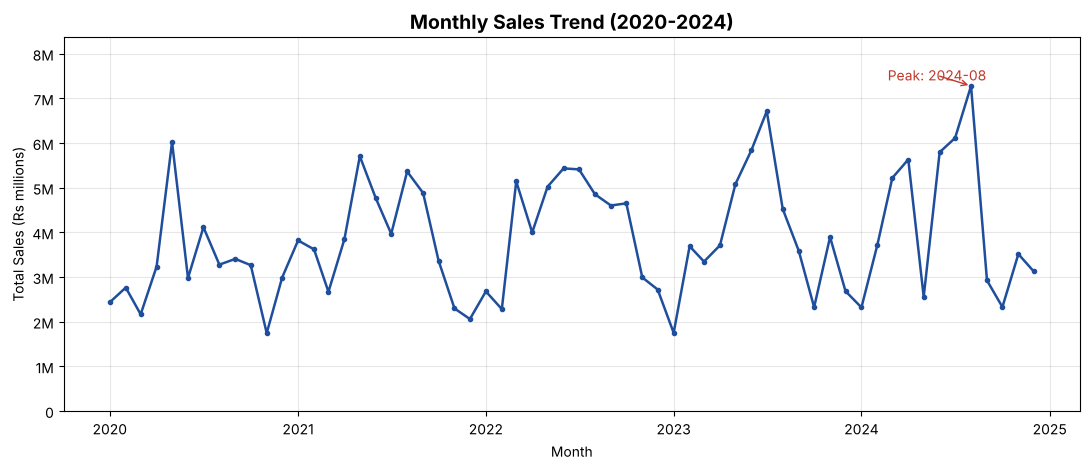

In [30]:
inr = mtick.FuncFormatter(lambda x, _: f"{x/1e6:,.0f}M" if abs(x) >= 1e6 else f"{x:,.0f}")

# 8.1 Monthly sales trend (line)
fig, ax = plt.subplots(figsize=(11, 4.8))
x = monthly_sales.index.to_timestamp()
ax.plot(x, monthly_sales.values, color="#1f4e9c", linewidth=1.8, marker="o", markersize=3)
peak_x, peak_y = best_ym.to_timestamp(), monthly_sales.max()
ax.annotate(f"Peak: {best_ym}", (peak_x, peak_y), textcoords="offset points", xytext=(-60, 4), color="#c0392b",
            arrowprops=dict(arrowstyle="->", color="#c0392b"))
ax.set_title("Monthly Sales Trend (2020-2024)", fontsize=14, fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Total Sales (Rs millions)")
ax.yaxis.set_major_formatter(inr)
ax.set_ylim(0, monthly_sales.max() * 1.15)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{CHART_DIR}/monthly_sales_trend.png", dpi=150)
plt.show()

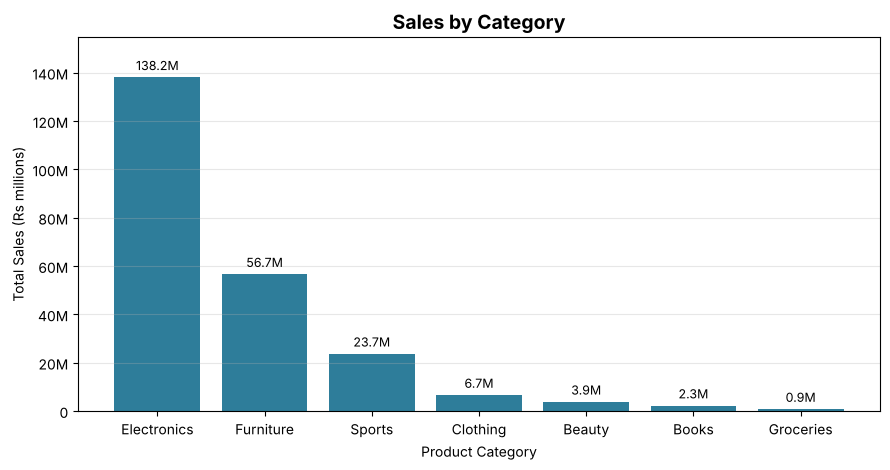

In [31]:
# 8.2 Sales by category (bar)
fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.bar(category_rev.index, category_rev.values, color="#2e7d9a")
ax.bar_label(bars, labels=[f"{v/1e6:,.1f}M" for v in category_rev.values], padding=3, fontsize=9)
ax.set_title("Sales by Category", fontsize=14, fontweight="bold")
ax.set_xlabel("Product Category")
ax.set_ylabel("Total Sales (Rs millions)")
ax.yaxis.set_major_formatter(inr)
ax.set_ylim(0, category_rev.max() * 1.12)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(f"{CHART_DIR}/sales_by_category.png", dpi=150)
plt.show()

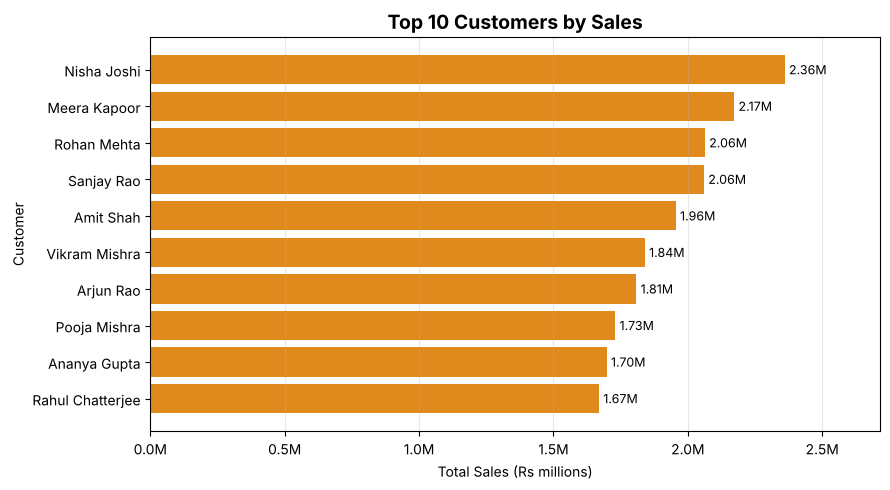

In [32]:
# 8.3 Top 10 customers by sales (horizontal bar)
top10 = top_customers.sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(top10.index, top10.values, color="#e08a1e")
ax.bar_label(bars, labels=[f"{v/1e6:,.2f}M" for v in top10.values], padding=3, fontsize=9)
ax.set_title("Top 10 Customers by Sales", fontsize=14, fontweight="bold")
ax.set_xlabel("Total Sales (Rs millions)")
ax.set_ylabel("Customer")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e6:,.1f}M"))
ax.set_xlim(0, top10.max() * 1.15)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(f"{CHART_DIR}/top10_customers.png", dpi=150)
plt.show()

## 9. Business Insights & Recommendations

In [33]:
top_region        = sales_by_region.index[0]
top_profit_cat    = profit_by_category.index[0]
top_customers_10  = top_customers.head(3)

print("Which region generated the highest revenue?")
print(f"  {top_region}: Rs {sales_by_region.iloc[0]:,.0f} ({sales_by_region.iloc[0]/total_sales:.1%} of sales)")
print("Which category was the most profitable?")
print(f"  {top_profit_cat}: Rs {profit_by_category['total_profit'].iloc[0]:,.0f} profit "
      f"({profit_by_category['margin_pct'].iloc[0]:.1f}% margin)")
print("Which month recorded the highest sales?")
print(f"  {best_ym}: Rs {monthly_sales.max():,.0f}  | strongest calendar month overall: {month_names[best_cal]}")
print("Which customers contributed the highest revenue?")
for name, val in top_customers_10.items():
    print(f"  {name}: Rs {val:,.0f}")

# supporting numbers for the three insights
top2_share = category_rev.head(2).sum() / total_sales
print(f"\nInsight 1: Electronics + Furniture = {top2_share:.1%} of sales")
print(f"Insight 2: Groceries margin = {profit_by_category.loc['Groceries','margin_pct']:.1f}% vs Electronics "
      f"{profit_by_category.loc['Electronics','margin_pct']:.1f}%")
summer = by_calendar_month.loc[[6, 7, 8]].sum() / total_sales
print(f"Insight 3: Jun-Aug = {summer:.1%} of sales (25% would be even)")
returns = (df["order_status"] == "Returned").mean()
cancels = (df["order_status"] == "Cancelled").mean()
print(f"Returns {returns:.1%} of orders, cancellations {cancels:.1%}; "
      f"sales tied up in Returned+Cancelled = {df[df['order_status'].isin(['Returned','Cancelled'])]['sales_amount'].sum()/total_sales:.1%}")

Which region generated the highest revenue?
  South: Rs 52,988,639 (22.8% of sales)
Which category was the most profitable?
  Electronics: Rs 16,644,957 profit (12.0% margin)
Which month recorded the highest sales?
  2024-08: Rs 7,280,800  | strongest calendar month overall: Jul
Which customers contributed the highest revenue?
  Nisha Joshi: Rs 2,360,876
  Meera Kapoor: Rs 2,172,911
  Rohan Mehta: Rs 2,063,837

Insight 1: Electronics + Furniture = 83.9% of sales
Insight 2: Groceries margin = 8.0% vs Electronics 12.0%
Insight 3: Jun-Aug = 32.9% of sales (25% would be even)
Returns 14.5% of orders, cancellations 8.2%; sales tied up in Returned+Cancelled = 20.4%


The one-page management report is provided separately as `Business_Analysis_Report.pdf`.